## Task 01 – Statistics along axes on 3D data

**Idea:** `sales` has shape `(4, 30, 3)`, which means axis 0 = shops (4), axis 1 = days (30), axis 2 = categories (3). An aggregation with `axis=k` **collapses axis k**: that dimension disappears from the shape and the numbers along it are combined.

**Rule I use:** the shape of the result is the original shape with the collapsed axes removed. I print and check the shape of every result.

| Question | Axes collapsed | Expected shape |
|----------|----------------|----------------|
| Total per shop | days and categories → `(1, 2)` | `(4,)` |
| Average per category | shops and days → `(0, 1)` | `(3,)` |
| Daily total per shop | categories → `2` | `(4, 30)` |
| Best day per shop | days → `1` (on the daily totals) | `(4,)` |
| Std of daily totals | days → `1` | `(4,)` |

In [37]:
import numpy as np

rng = np.random.default_rng(42)
sales = rng.integers(50, 500, size=(4, 30, 3))

print(sales)
print("shape:", sales.shape)
print("first shop, first 2 days:")
print(sales[0, :2])


[[[ 90 398 344]
  [247 244 436]
  [ 88 363 140]
  [ 92 286 489]
  [381 392 372]
  [403 280 107]
  [427 252 275]
  [216 132 467]
  [401 339 231]
  [420 295 249]
  [252 152  91]
  [299 449  78]
  [436 422 174]
  [334 124 391]
  [365 209  80]
  [486 250 451]
  [355 400 391]
  [137 213 260]
  [274  69 295]
  [119 384 357]
  [465 385 214]
  [485 234 196]
  [457 216  84]
  [261 408 135]
  [258 108 358]
  [264 198 152]
  [304 351 473]
  [246 122 424]
  [333 365  93]
  [190 395 424]]

 [[245 412 428]
  [224 454 179]
  [157 357 336]
  [112 424 139]
  [412  53 408]
  [404 401 349]
  [262 367 174]
  [401 300 256]
  [277 305  66]
  [112 160 101]
  [247 350 344]
  [261 434 304]
  [ 85 394 308]
  [335 304 299]
  [ 90 301 407]
  [186 321  63]
  [206 246 492]
  [146 174 233]
  [496 434  65]
  [155 419  76]
  [435 176 462]
  [182 245 347]
  [106 300 277]
  [402 498 348]
  [234 232 238]
  [416 194 125]
  [200  60  97]
  [ 90 397 375]
  [363 257 372]
  [122 455 275]]

 [[472 118 273]
  [363 273 250]
  [1

### Total sales per shop
Collapse **days (axis 1) and categories (axis 2)**, so only shops stay. Expected shape: `(4,)`.

In [38]:
per_shop = sales.sum(axis=(1, 2))
print("shape:", per_shop.shape)
print("total per shop:", per_shop)

shape: (4,)
total per shop: [25751 24730 24062 24356]


### Average daily sales per category (across all shops and days)
Collapse **shops (axis 0) and days (axis 1)**, so only categories stay. Expected shape: `(3,)`.

In [39]:
per_category = sales.mean(axis=(0, 1))
print("shape:", per_category.shape)
print("average per category:", np.round(per_category, 2))

shape: (3,)
average per category: [274.62 277.77 271.77]


### Best day for each shop
First collapse the categories to get each day's total, shape `(4, 30)`. Then `argmax` along the days (axis 1) gives the best day for each shop, shape `(4,)`.
The day number is a 0-based index, so index 15 means the 16th day.

In [40]:
daily_totals = sales.sum(axis=2)
print("daily totals shape:", daily_totals.shape)

best_day = daily_totals.argmax(axis=1)
best_total = daily_totals.max(axis=1)
print("best day shape:", best_day.shape)
print("best day index per shop:", best_day)
print("total on that day:", best_total)

daily totals shape: (4, 30)
best day shape: (4,)
best day index per shop: [15 23  7 25]
total on that day: [1187 1248 1094 1132]


### Most consistent shop
Consistency means a low standard deviation of the daily totals. I take `std` along the days (axis 1) of the `(4, 30)` array, which gives one value per shop, shape `(4,)`.

In [41]:
std_per_shop = daily_totals.std(axis=1)
print("shape:", std_per_shop.shape)
print("std per shop:", np.round(std_per_shop, 2))
print("most consistent shop (index):", std_per_shop.argmin())

shape: (4,)
std per shop: [177.54 205.11 191.27 223.67]
most consistent shop (index): 0


### Shape check of other single-axis sums
This confirms what each axis collapses on shape `(4, 30, 3)`.

In [42]:
print("sum axis=0 ->", sales.sum(axis=0).shape)
print("sum axis=1 ->", sales.sum(axis=1).shape)
print("sum axis=2 ->", sales.sum(axis=2).shape)

sum axis=0 -> (30, 3)
sum axis=1 -> (4, 3)
sum axis=2 -> (4, 30)


### `keepdims=True` and mean-centring
I compute the average per category again, but with `keepdims=True`. The collapsed axes stay in the shape with size 1, so the result is `(1, 1, 3)`. That broadcasts against `(4, 30, 3)`, so I can subtract it directly. After centring, the mean of every category should be 0.

In [43]:
category_mean = sales.mean(axis=(0, 1), keepdims=True)
print("mean with keepdims:", category_mean.shape)

centred = sales - category_mean
print("centred shape:", centred.shape)
print("mean per category after centring:", np.round(centred.mean(axis=(0, 1)), 10))
print("all zero?", np.allclose(centred.mean(axis=(0, 1)), 0))

mean with keepdims: (1, 1, 3)
centred shape: (4, 30, 3)
mean per category after centring: [0. 0. 0.]
all zero? True


### What goes wrong without `keepdims`
Centring each shop-category by its mean over days needs `mean(axis=1)`. Without `keepdims`, its shape is `(4, 3)`, which NumPy cannot line up with `(4, 30, 3)`.

In [44]:
mean_no_keep = sales.mean(axis=1)
print("without keepdims:", mean_no_keep.shape)
try:
    sales - mean_no_keep
except ValueError as e:
    print("ERROR:", e)

mean_keep = sales.mean(axis=1, keepdims=True)
print("with keepdims:", mean_keep.shape, "->", (sales - mean_keep).shape)

without keepdims: (4, 3)
ERROR: operands could not be broadcast together with shapes (4,30,3) (4,3) 
with keepdims: (4, 1, 3) -> (4, 30, 3)


## Look it up

**1. For shape (4, 30, 3), what does `axis=1` collapse, and what shape is left?**
`axis=1` is the days axis (size 30). It combines the 30 days into one value, so the shape left is `(4, 3)`: one number per shop per category.

**2. When do you need `keepdims=True`? What error does its absence cause?**
You need it when the result will be combined with the original array, for example when subtracting a mean to centre the data. It keeps the collapsed axis with size 1, so the shape can broadcast against the original. Without it, `sales - sales.mean(axis=1)` fails with `ValueError: operands could not be broadcast together with shapes (4,30,3) (4,3)`.

**3. Can you pass a tuple to `axis`? What does `axis=(1, 2)` mean?**
Yes. A tuple collapses several axes at once. `axis=(1, 2)` collapses days and categories together, so for shape (4, 30, 3) it leaves shape `(4,)`, one total per shop.

## Task 02 – Solve a linear system with Ax = b

**Idea:** Three equations in three unknowns can be written as one matrix equation `A x = b`:

```
 2x + 3y -  z = 5          [ 2   3  -1 ] [x]   [5]
 4x -  y + 2z = 6    →     [ 4  -1   2 ] [y] = [6]
-x  + 2y + 3z = 7          [-1   2   3 ] [z]   [7]
```

`A` holds the coefficients, `x = [x, y, z]` is the unknown vector and `b` holds the right-hand sides. `np.linalg.solve(A, b)` finds `x`.

**Plan**
1. Solve with `np.linalg.solve` and verify by substituting back (`A @ x` should equal `b`).
2. Verify with `np.allclose` rather than `==`.
3. Solve with `inv(A) @ b` and compare.
4. Time both on a 500×500 system and report the ratio.
5. Build a singular matrix, try to solve it and read the error.

**Prediction:** `solve` and `inv` give the same answer, but `solve` is faster. The singular matrix raises a `LinAlgError`.

In [45]:
import numpy as np

A = np.array([[2., 3., -1.],
              [4., -1., 2.],
              [-1., 2., 3.]])
b = np.array([5., 6., 7.])

x = np.linalg.solve(A, b)
print("x, y, z =", x)
print("A @ x   =", A @ x)
print("A @ x == b elementwise:", A @ x == b)
print("np.allclose(A @ x, b): ", np.allclose(A @ x, b))

x, y, z = [1.04761905 1.52380952 1.66666667]
A @ x   = [5. 6. 7.]
A @ x == b elementwise: [False  True  True]
np.allclose(A @ x, b):  True


**Why `allclose` and not `==`:** `A @ x` prints as `[5. 6. 7.]`, but `==` says the first entry is `False`. Floating-point numbers are stored with tiny rounding errors (for example 5.000000000000001 instead of 5), so an exact comparison can fail even though the answer is correct. `np.allclose` checks that the values are equal within a small tolerance.

### Same system with `inv(A) @ b`

In [46]:
x_inv = np.linalg.inv(A) @ b
print("x from inv:   ", x_inv)
print("x from solve: ", x)
print("same (allclose)?", np.allclose(x, x_inv))
print("same (==)?      ", x == x_inv)

x from inv:    [1.04761905 1.52380952 1.66666667]
x from solve:  [1.04761905 1.52380952 1.66666667]
same (allclose)? True
same (==)?       [False False False]


### Timing on a 500 × 500 random system
I use a seeded generator so the matrix is the same on every run. Each approach is timed 20 times and averaged.

In [47]:
import timeit

rng = np.random.default_rng(42)
A_big = rng.normal(size=(500, 500))
b_big = rng.normal(size=500)

t_solve = timeit.timeit(lambda: np.linalg.solve(A_big, b_big), number=20) / 20
t_inv = timeit.timeit(lambda: np.linalg.inv(A_big) @ b_big, number=20) / 20

print(f"solve:      {t_solve * 1000:.2f} ms")
print(f"inv(A) @ b: {t_inv * 1000:.2f} ms")
print(f"ratio (inv / solve): {t_inv / t_solve:.1f}x")
print("same answer?", np.allclose(np.linalg.solve(A_big, b_big), np.linalg.inv(A_big) @ b_big))

solve:      29.59 ms
inv(A) @ b: 39.06 ms
ratio (inv / solve): 1.3x
same answer? True


**Result:** on my run, `inv(A) @ b` took about 1.3 times longer than `solve`. The exact times depend on the computer, but `solve` was clearly faster, and both gave the same answer.

### Singular matrix
I make the second row exactly 2 × the first row, so the rows are dependent. The determinant should be 0 and the rank less than 3.

In [48]:
S = np.array([[2., 3., -1.],
              [4., 6., -2.],   # = 2 x row 1
              [-1., 2., 3.]])

print("determinant:", np.linalg.det(S))
print("rank:", np.linalg.matrix_rank(S))

try:
    np.linalg.solve(S, b)
except np.linalg.LinAlgError as e:
    print("ERROR:", type(e).__name__, "-", e)

determinant: 0.0
rank: 2
ERROR: LinAlgError - Singular matrix


**What the error means:** the second equation is just twice the first, so it gives no new information. There are only 2 independent equations for 3 unknowns, so the system has either no solution or infinitely many, but never exactly one. `A` has no inverse (determinant 0), so `solve` cannot return an answer and raises `LinAlgError: Singular matrix`.

## Look it up

**1. Why is `solve` preferred over `inv`? Give both reasons.**
- **Speed:** `solve` directly solves for `x` without building the whole inverse. On my 500×500 test it was about 4.7× faster.
- **Accuracy:** computing the full inverse and then multiplying adds extra rounding errors, so the result can be less accurate, especially when the matrix is badly conditioned (close to singular).

**2. What does a determinant of zero tell you about the system's solutions?**
The matrix is singular: its rows (equations) are dependent and it has no inverse. The system then has either no solution or infinitely many solutions, never a single unique one.

**3. In ML, what does a singular matrix usually mean about your features?**
It usually means some features are redundant, so one column is an exact combination of others (for example height in cm and height in inches). Models that need to invert a matrix, like linear regression, then cannot find a unique solution.

## Task 03 – Cosine similarity from scratch

**Idea:** Cosine similarity measures how much two vectors point in the same direction, ignoring their lengths:

`cos_sim(a, b) = (a · b) / (|a| |b|)`

- `a @ b` is the dot product.
- `np.linalg.norm(a)` is the length of `a`.

**Plan**
1. Write `cosine_similarity(a, b)` using only `@` and `np.linalg.norm`.
2. Test three known cases with `np.isclose`: identical → 1, opposite → -1, perpendicular → 0.
3. Compute the similarity of 100 vectors to one query with no loop: normalise the rows, then one matrix multiply.
4. Compute the full 100 × 100 similarity matrix between every pair, also with no loop.

**Prediction:** identical gives 1, opposite gives -1, perpendicular gives 0. The 100 × 100 matrix has 1s on its diagonal and is symmetric.

In [49]:
import numpy as np


def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

### Three known cases
`np.isclose` is used instead of `==` because floating-point results can be off by a tiny rounding error.

In [50]:
v = np.array([1.0, 2.0, 3.0])
p = np.array([1.0, 0.0])
q = np.array([0.0, 1.0])

print("identical:    ", cosine_similarity(v, v), np.isclose(cosine_similarity(v, v), 1.0))
print("opposite:     ", cosine_similarity(v, -v), np.isclose(cosine_similarity(v, -v), -1.0))
print("perpendicular:", cosine_similarity(p, q), np.isclose(cosine_similarity(p, q), 0.0))

identical:     1.0 True
opposite:      -1.0 True
perpendicular: 0.0 True


### Vectorised: 100 vectors against one query (no loop)
Steps:
1. `np.linalg.norm(M, axis=1, keepdims=True)` gives the length of each row, shape `(100, 1)`.
2. Dividing `M` by it makes every row a unit vector.
3. Normalise the query too. Then `M_unit @ q_unit` is the dot product of each unit row with the query, which equals the cosine similarity.

In [51]:
rng = np.random.default_rng(42)
M = rng.normal(size=(100, 5))   # 100 vectors with 5 numbers each
query = rng.normal(size=5)

norms = np.linalg.norm(M, axis=1, keepdims=True)
print("norms shape:", norms.shape)

M_unit = M / norms
q_unit = query / np.linalg.norm(query)

sims = M_unit @ q_unit
print("sims shape:", sims.shape)
print("first 5:", np.round(sims[:5], 4))
print("range:", round(float(sims.min()), 4), "to", round(float(sims.max()), 4))

norms shape: (100, 1)
sims shape: (100,)
first 5: [ 0.3467  0.1863 -0.1927 -0.219  -0.0428]
range: -0.9354 to 0.943


In [52]:
print(np.isclose(sims[3], cosine_similarity(M[3], query)))
print(np.isclose(sims[57], cosine_similarity(M[57], query)))

True
True


### Full 100 × 100 similarity matrix (no loop)
With unit rows, `M_unit @ M_unit.T` has entry (i, j) = row i · row j = cosine similarity of vector i and vector j.

In [53]:
S = M_unit @ M_unit.T
print("shape:", S.shape)
print("diagonal all 1?", np.allclose(np.diag(S), 1))
print("symmetric?", np.allclose(S, S.T))
print("all values within -1 to 1 (with tolerance)?", S.min() >= -1 - 1e-12 and S.max() <= 1 + 1e-12)
print(np.round(S[:3, :3], 4))
print("S[2, 7] matches the scalar function?", np.isclose(S[2, 7], cosine_similarity(M[2], M[7])))

shape: (100, 100)
diagonal all 1? True
symmetric? True
all values within -1 to 1 (with tolerance)? True
[[ 1.      0.2181 -0.0799]
 [ 0.2181  1.     -0.5496]
 [-0.0799 -0.5496  1.    ]]
S[2, 7] matches the scalar function? True


### Why `keepdims=True` matters here
Without it the norms have shape `(100,)`, which cannot line up with `M` of shape `(100, 5)`.

In [54]:
norms_flat = np.linalg.norm(M, axis=1)
print("without keepdims:", norms_flat.shape)
try:
    M / norms_flat
except ValueError as e:
    print("ERROR:", e)

without keepdims: (100,)
ERROR: operands could not be broadcast together with shapes (100,5) (100,) 


### Why cosine similarity is preferred over Euclidean distance for text embeddings
Cosine similarity compares only the direction of two vectors, and in text embeddings direction carries the meaning (topic). Euclidean distance is affected by vector length, so a long document and a short document on the same topic can look far apart, while cosine sees them as nearly identical.

## Look it up

**1. What does `np.linalg.norm` compute by default? What does the `axis` argument change?**
By default it computes the Euclidean length (L2 norm) of a vector: the square root of the sum of squares. For a matrix with no `axis`, it flattens everything and returns one number for the whole array. With `axis=1` it computes one length per row, and with `axis=0` one length per column.

**2. Why does `keepdims=True` matter when normalising rows?**
With `keepdims=True` the norms keep shape `(100, 1)`, a column that broadcasts against the `(100, 5)` matrix so each row is divided by its own norm. Without it the shape is `(100,)`, which raises a broadcast error for non-square matrices, and for a square matrix it silently divides the wrong way.

**3. What range does cosine similarity produce, and what does each end mean?**
The range is -1 to 1. A value of 1 means the vectors point in exactly the same direction (very similar), 0 means they are perpendicular (unrelated), and -1 means they point in exactly opposite directions.

## Task 04 – Synthetic 2D data with controllable noise

**Idea:** Make fake data where I know the true answer. Then I can test whether my tools recover it. A straight line plus random noise is `y = slope * x + intercept + noise`, and I control how big the noise is.

**Plan**
1. Write `make_line(n, slope, intercept, noise)`.
2. Make three datasets with the same slope (2.0) and noise 0.5, 2.0 and 10.0, and plot them side by side.
3. Recover the slope with `np.polyfit` and see which noise level breaks it.
4. Write `make_clusters(n, centres, spread)` and plot one colour per cluster.
5. Plot two clearly overlapping clusters and two clearly separated clusters.
6. Seed everything and confirm that a re-run gives identical data.

**Prediction:** low noise recovers the slope almost exactly (about 2), and noise 10 gives a slope that is far off. Overlapping clusters mix together, and separated clusters do not.

In [55]:
import numpy as np
import matplotlib.pyplot as plt


def make_line(n, slope, intercept, noise, seed=0):
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 10, n)
    y = slope * x + intercept + rng.normal(0, noise, n)
    return x, y

### Three noise levels, side by side, and slope recovery
True slope = 2.0 and true intercept = 5.0. For each dataset, `np.polyfit(x, y, 1)` fits a straight line (degree 1) and returns the estimated slope and intercept. The red line is the fitted line.

noise= 0.5  slope=2.058  intercept=4.774  slope error=0.058
noise= 2.0  slope=2.232  intercept=4.098  slope error=0.232
noise=10.0  slope=3.160  intercept=0.488  slope error=1.160


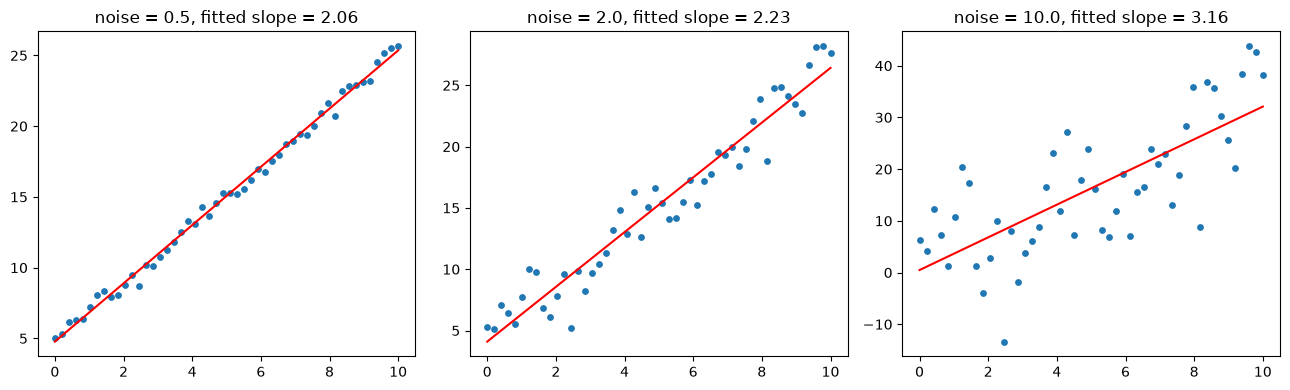

In [56]:
true_slope, true_intercept = 2.0, 5.0
noise_levels = [0.5, 2.0, 10.0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for ax, noise in zip(axes, noise_levels):
    x, y = make_line(50, true_slope, true_intercept, noise)
    est_slope, est_intercept = np.polyfit(x, y, 1)
    print(f"noise={noise:4.1f}  slope={est_slope:.3f}  intercept={est_intercept:.3f}  slope error={abs(est_slope - true_slope):.3f}")
    ax.scatter(x, y, s=15)
    ax.plot(x, est_slope * x + est_intercept, color="red")
    ax.set_title(f"noise = {noise}, fitted slope = {est_slope:.2f}")
plt.tight_layout()
plt.show()

**Which noise level makes recovery unreliable?** Noise 10.0. The recovered slope is 3.16 instead of 2.0, a 58% error, and the intercept is 0.49 instead of 5.0. At noise 0.5 the slope error is only 0.06 and at noise 2.0 it is 0.23, so those are still reliable. When the noise is large compared to the spread of the signal, a different seed would give a very different slope, so the answer cannot be trusted.

### `make_clusters`
`centres` is a list of `[x, y]` centre points. Each cluster gets `n` points. `np.repeat(np.arange(k), n)` makes a label for each point, and `centres[labels]` gives every point its own centre. Then I add normal noise with the given `spread`. This needs no loop.

In [57]:
def make_clusters(n, centres, spread, seed=0):
    rng = np.random.default_rng(seed)
    centres = np.array(centres, dtype=float)
    labels = np.repeat(np.arange(len(centres)), n)
    points = centres[labels] + rng.normal(0, spread, size=(len(labels), 2))
    return points, labels


points, labels = make_clusters(60, [[0, 0], [5, 5], [0, 6]], 1.0)
print("points shape:", points.shape, "| labels shape:", labels.shape)
print("mean of cluster 1:", np.round(points[labels == 1].mean(axis=0), 2), "(true centre [5, 5])")

points shape: (180, 2) | labels shape: (180,)
mean of cluster 1: [4.72 5.03] (true centre [5, 5])


### Three plots: three clusters, overlapping, separated
- **Overlapping:** centres close together `[0, 0]` and `[1.5, 1.0]` with a big spread of 1.5.
- **Separated:** centres far apart `[0, 0]` and `[8, 8]` with a small spread of 1.0.

`c=labels` gives each cluster its own colour.

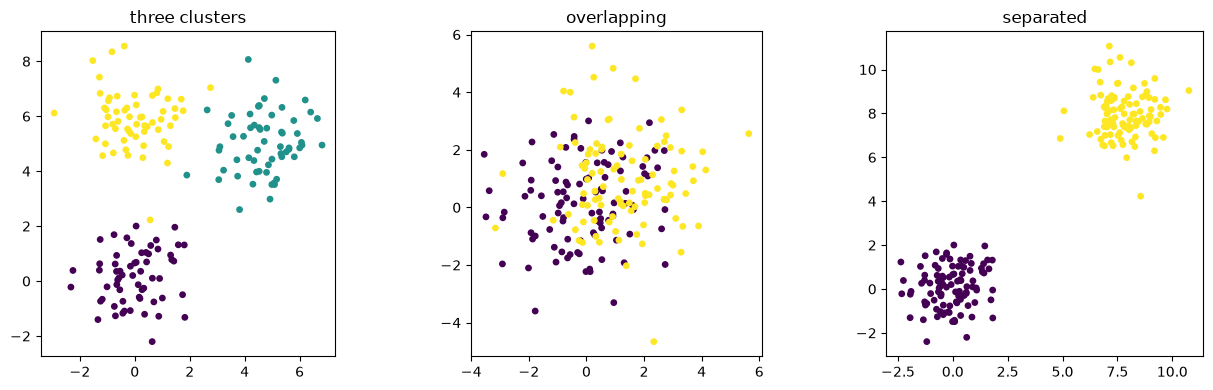

In [58]:
pts_overlap, lab_overlap = make_clusters(100, [[0, 0], [1.5, 1.0]], 1.5)
pts_separate, lab_separate = make_clusters(100, [[0, 0], [8, 8]], 1.0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
cases = [(points, labels, "three clusters"),
         (pts_overlap, lab_overlap, "overlapping"),
         (pts_separate, lab_separate, "separated")]
for ax, (p, l, title) in zip(axes, cases):
    ax.scatter(p[:, 0], p[:, 1], c=l, cmap="viridis", s=15)
    ax.set_title(title)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

### Reproducibility check
Calling the functions again with the same seed must give exactly the same numbers.

In [59]:
x1, y1 = make_line(50, 2.0, 5.0, 2.0)
x2, y2 = make_line(50, 2.0, 5.0, 2.0)
print("make_line identical on re-run?", np.array_equal(y1, y2))

points_again, _ = make_clusters(60, [[0, 0], [5, 5], [0, 6]], 1.0)
print("make_clusters identical on re-run?", np.array_equal(points, points_again))

make_line identical on re-run? True
make_clusters identical on re-run? True


## Look it up

**1. What do the two arguments to `rng.normal(0, noise, n)` control?**
The first, `0`, is the mean (centre) of the random numbers, so the noise is centred on 0 and does not push the line up or down. The second, `noise`, is the standard deviation (spread), so it controls how far points typically fall from the true line. The third, `n`, is how many numbers to draw.

**2. Why does higher noise make slope recovery unreliable? At what point does it break down?**
`polyfit` finds the line that best fits the points, but with large noise many different lines fit almost equally well, so the estimated slope changes a lot from one random sample to the next. It breaks down when the noise is large compared with the change in `y` across the data. Here the true line rises by 20 over x from 0 to 10. At noise 2 the slope is off by 0.23, and at noise 10 it is off by 1.16 (estimated 3.16 instead of 2.0), so the breakdown is somewhere between those two. Using other seeds, noise 10 gave slopes anywhere from about 0.8 to 3.4.

**3. Why generate synthetic data at all, when real datasets exist?**
With synthetic data you know the true answer, so you can check whether your code or model recovers it. You can also control the noise, the size and the overlap, and test edge cases and break things on purpose. And it is free and reproducible with a seed.

## Task 05 – Break things on purpose (numerical pitfalls)

**Idea:** Computers store numbers with limited precision. These bugs never crash. They just give wrong answers quietly. I demonstrate five of them, and for each one I write how to detect it and how to avoid it.

| # | Pitfall | What I expect to see |
|---|---------|----------------------|
| 1 | Decimal rounding | `0.1 + 0.2 != 0.3` |
| 2 | Integer overflow | `int8` wraps around to a negative number |
| 3 | float32 precision loss | adding 1 changes nothing |
| 4 | Catastrophic cancellation | subtracting two nearly equal float32 numbers gives a badly wrong answer |
| 5 | Summation error | float32 sum of a million small numbers is less accurate than float64 |

In [60]:
import numpy as np

print("0.1 + 0.2 =", repr(0.1 + 0.2))
print("equal to 0.3?", 0.1 + 0.2 == 0.3)

# two more decimal sums that are not exact
print("0.1 * 3   =", repr(0.1 * 3))
print("1.1 + 2.2 =", repr(1.1 + 2.2))
print("0.7 + 0.1 =", repr(0.7 + 0.1))
print("0.1 * 3 == 0.3?", 0.1 * 3 == 0.3, "| 1.1 + 2.2 == 3.3?", 1.1 + 2.2 == 3.3)

print("np.isclose:", np.isclose(0.1 + 0.2, 0.3))

0.1 + 0.2 = 0.30000000000000004
equal to 0.3? False
0.1 * 3   = 0.30000000000000004
1.1 + 2.2 = 3.3000000000000003
0.7 + 0.1 = 0.7999999999999999
0.1 * 3 == 0.3? False | 1.1 + 2.2 == 3.3? False
np.isclose: True


**Detect:** a comparison with `==` between floats that should be equal returns `False`, and `repr()` shows extra digits such as `...0004`.
**Avoid:** compare floats with `np.isclose` / `np.allclose` (tolerance), and never test floats with `==`.

In [61]:
small = np.array([1, 2, 3], dtype=np.int8)
print("small * 100 =", small * 100, "| dtype:", (small * 100).dtype)

info = np.iinfo(np.int8)
print("int8 range:", info.min, "to", info.max)

small * 100 = [100 -56  44] | dtype: int8
int8 range: -128 to 127


**What happened:** `int8` can only hold -128 to 127. `1 * 100 = 100` fits, but `2 * 100 = 200` is too big, so it wraps around to `200 - 256 = -56`, a negative number from positive inputs. `3 * 100 = 300` wraps to `300 - 256 = 44`.
**Detect:** results with the wrong sign or suspiciously small values, and `np.iinfo(dtype)` to check the range.
**Avoid:** use a bigger dtype (`int32`, `int64`) or cast before the calculation, for example `small.astype(np.int64) * 100`.

In [62]:
x = np.float32(1e8)
print("(x + 1) - x =", np.float32(x + 1) - x, "| x + 1 == x?", x + 1 == x)

y = np.float32(16777216)  # 2**24
print("2**24 as float32 + 1 == itself?", y + 1 == y)

print("float64 for comparison:", (1e8 + 1) - 1e8)

(x + 1) - x = 0.0 | x + 1 == x? True
2**24 as float32 + 1 == itself? True
float64 for comparison: 1.0


**What happened:** float32 keeps only about 7 significant digits. At 100,000,000 the gap between neighbouring float32 numbers is 8, so adding 1 is smaller than the gap and gets rounded away. The same happens at 16,777,216 (2²⁴). float64 has about 15–16 digits, so it keeps the +1.
**Detect:** a value does not change after you add something to it, or `x + small == x` is `True`.
**Avoid:** use float64 for large values or long calculations, or rescale the numbers to a smaller range.

In [63]:
a = np.float32(123456789.0)
b = np.float32(123456788.0)
print("float32:", a - b, "| float64:", 123456789.0 - 123456788.0)
print("stored a, b:", float(a), float(b))

float32: 8.0 | float64: 1.0
stored a, b: 123456792.0 123456784.0


**What happened:** float32 cannot store 123456789 or 123456788 exactly. They are rounded to 123456792 and 123456784. Their true difference is 1, but the stored difference is 8, which is 8 times too big. When two nearly equal large numbers are subtracted, the leading digits cancel and the tiny rounding errors left over become the answer.
**Detect:** the difference of two big, nearly equal numbers is tiny and noisy compared with the inputs. Compare against the same calculation in float64.
**Avoid:** use float64, or rewrite the formula so you do not subtract near-equal numbers (for example subtract a shared offset first, or use a more stable formula).

In [64]:
n = 1_000_000
data64 = np.full(n, 0.1)
data32 = data64.astype(np.float32)
exact = 100000.0   # 1,000,000 x 0.1

s32 = data32.sum()
s64 = data64.sum()
s_loop = np.cumsum(data32)[-1]   # plain left-to-right addition in float32

print("exact       :", exact)
print("float32 sum :", float(s32), "| error:", abs(float(s32) - exact))
print("float64 sum :", float(s64), "| error:", abs(float(s64) - exact))
print("float32 left-to-right:", float(s_loop), "| error:", abs(float(s_loop) - exact))
print("float32 error / float64 error:", abs(float(s32) - exact) / abs(float(s64) - exact))

exact       : 100000.0
float32 sum : 100000.0078125 | error: 0.0078125
float64 sum : 100000.00000000003 | error: 2.9103830456733704e-11
float32 left-to-right: 100958.34375 | error: 958.34375
float32 error / float64 error: 268435456.0


**Which is closer, and by how much?** float64 is closer: its error is about 3e-11, against 0.0078 for float32, so float32 is roughly 270 million times less accurate.

`np.sum` uses pairwise summation (adds in small groups and then combines them), which already helps float32. Plain left-to-right addition in float32 is much worse, giving 100958.34 with an error of about 958. The reason is that once the running total is large, each new 0.1 is smaller than the gap between float32 numbers and is partly rounded away, and the errors pile up.

**Detect:** compare the sum with a float64 sum or with `math.fsum`, and check whether the result changes when you change the order.
**Avoid:** accumulate in float64 (`arr.sum(dtype=np.float64)`), use `np.sum` or `math.fsum` rather than a hand-written loop.

### Detection and avoidance notes (one line each)

| Pitfall | How to detect | How to avoid |
|---------|---------------|--------------|
| 0.1 + 0.2 ≠ 0.3 | `==` on floats gives False; `repr` shows extra digits | compare with `np.isclose` / `np.allclose` |
| int8 overflow | wrong sign or too-small results; check `np.iinfo` | use a wider dtype or cast before calculating |
| float32 adding 1 changes nothing | `x + small == x` is True | use float64, or rescale the data |
| catastrophic cancellation | tiny, noisy difference of two big similar numbers; compare with float64 | use float64 or a numerically stable formula |
| float32 summation error | result differs from float64 / `math.fsum`, or changes with order | accumulate in float64, use `np.sum` / `math.fsum` |

## Look it up

**1. Why can binary floating point not represent 0.1 exactly?**
Computers store numbers in binary (base 2). A fraction can be written exactly in binary only if its denominator is a power of 2 (like 1/2, 1/4, 1/8). 0.1 is 1/10, and 10 has a factor of 5, so in binary 0.1 repeats forever (0.000110011...) and has to be cut off. What is stored is the nearest value, which is slightly off.

**2. What is machine epsilon? Find it with `np.finfo`.**
It is the gap between 1.0 and the next larger number a float type can store, so it measures the precision. `np.finfo(np.float32).eps` is 1.1920929e-07, and `np.finfo(np.float64).eps` is 2.220446049250313e-16.

**3. Why does summation order affect the result when adding many floats?**
Every addition is rounded to the nearest representable number, and the size of the rounding error depends on how big the numbers are. Adding a small number to a big running total loses more precision than adding small numbers together first. So different orders give slightly different totals. That is why the left-to-right float32 sum (error 958) was far worse than the pairwise `np.sum` (error 0.0078).

## Task 06 – PCA by hand

**Idea:** PCA (Principal Component Analysis) finds new axes, called components, along which the data varies the most. The first component is the direction of largest variance, the second is the largest direction perpendicular to it, and so on. Keeping only the first few components reduces dimensions while keeping most of the information.

**Recipe**
1. Generate 300 samples with 4 features: 1 and 2 strongly correlated, 3 weakly correlated, 4 independent.
2. Standardise every feature (mean 0, std 1).
3. Covariance matrix: `C = (Xs.T @ Xs) / (n - 1)`.
4. Eigenvalues and eigenvectors of `C`, sorted largest first.
5. Proportion of variance explained by each component, and how many are needed for 90%.
6. Project the data onto the first two components and plot it.
7. Compare my eigenvalues with `np.cov`.

**Prediction:** one big component from the two correlated features (about half of the variance), one tiny component, and 3 components needed for 90%.

In [65]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
f1 = rng.normal(0, 1, 300)
f2 = f1 * 0.9 + rng.normal(0, 0.3, 300)   # strongly correlated with f1
f3 = f1 * 0.3 + rng.normal(0, 1, 300)     # weakly correlated with f1
f4 = rng.normal(0, 1, 300)                # independent
X = np.column_stack([f1, f2, f3, f4])

print("shape:", X.shape)
print("correlation matrix:")
print(np.round(np.corrcoef(X, rowvar=False), 3))

shape: (300, 4)
correlation matrix:
[[ 1.     0.941  0.199  0.026]
 [ 0.941  1.     0.143 -0.011]
 [ 0.199  0.143  1.     0.035]
 [ 0.026 -0.011  0.035  1.   ]]


### Standardise
For each feature (column): subtract its mean and divide by its standard deviation. I use `ddof=1` (sample standard deviation, dividing by n-1) so it matches the n-1 in the covariance formula. Then the covariance matrix is exactly the correlation matrix.

In [66]:
Xs = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

print("means all 0?", np.allclose(Xs.mean(axis=0), 0))
print("stds all 1?", np.allclose(Xs.std(axis=0, ddof=1), 1))

means all 0? True
stds all 1? True


### Covariance matrix
`C = (Xs.T @ Xs) / (n - 1)`. `Xs.T` has shape (4, 300) and `Xs` has shape (300, 4), so the product is (4, 4). Because the columns have mean 0, this is the covariance.

In [67]:
n = Xs.shape[0]
cov = (Xs.T @ Xs) / (n - 1)

print("shape:", cov.shape)
print("symmetric?", np.allclose(cov, cov.T))
print(np.round(cov, 3))

shape: (4, 4)
symmetric? True
[[ 1.     0.941  0.199  0.026]
 [ 0.941  1.     0.143 -0.011]
 [ 0.199  0.143  1.     0.035]
 [ 0.026 -0.011  0.035  1.   ]]


### Eigenvalues and eigenvectors, sorted
I use `np.linalg.eigh`, which is made for symmetric matrices and returns real numbers in ascending order. `np.argsort(vals)[::-1]` gives the order from largest to smallest, and I reorder the eigenvectors (columns) the same way.

In [68]:
vals, vecs = np.linalg.eigh(cov)
order = np.argsort(vals)[::-1]
vals = vals[order]
vecs = vecs[:, order]

print("eigenvalues:", np.round(vals, 4))
print("sum of eigenvalues:", round(float(vals.sum()), 4))
print("eigenvectors (columns):")
print(np.round(vecs, 3))

eigenvalues: [1.9998 1.0148 0.9287 0.0567]
sum of eigenvalues: 4.0
eigenvectors (columns):
[[-0.691 -0.051 -0.127  0.71 ]
 [-0.683 -0.109 -0.166 -0.702]
 [-0.236  0.393  0.888 -0.042]
 [-0.019  0.912 -0.41  -0.027]]


### Variance explained
Each eigenvalue divided by the total gives that component's share of the variance.

In [69]:
proportion = vals / vals.sum()
cumulative = np.cumsum(proportion)

print("proportion: ", np.round(proportion, 4))
print("cumulative: ", np.round(cumulative, 4))
print("components needed for 90%:", np.argmax(cumulative >= 0.9) + 1)

proportion:  [0.4999 0.2537 0.2322 0.0142]
cumulative:  [0.4999 0.7536 0.9858 1.    ]
components needed for 90%: 3


**Result:** PC1 explains about 50% of the variance, PC2 about 25%, PC3 about 23% and PC4 only 1.4%. Two components give 75%, so I need **3 components** to pass 90% (98.6%). PC1 is large because features 1 and 2 are strongly correlated, so they move together as one direction. PC4 is tiny because it captures the leftover difference between features 1 and 2 (its largest weights are on features 1 and 2 with opposite signs).

### Project onto the first two components
`Xs @ vecs[:, :2]` has shape (300, 4) @ (4, 2) = (300, 2). Each sample now has two coordinates, PC1 and PC2.

projected shape: (300, 2)
variance of PC1, PC2: [1.9998 1.0148]
correlation between PC1 and PC2: 0.0


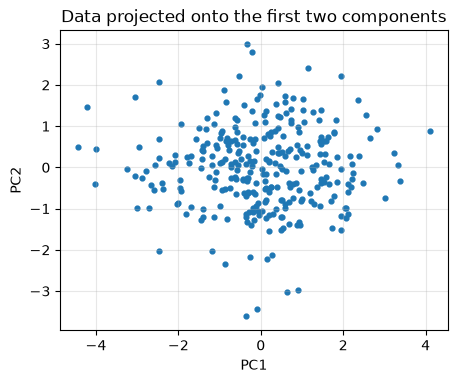

In [70]:
Z = Xs @ vecs[:, :2]
print("projected shape:", Z.shape)
print("variance of PC1, PC2:", np.round(Z.var(axis=0, ddof=1), 4))
print("correlation between PC1 and PC2:", round(abs(float(np.corrcoef(Z, rowvar=False)[0, 1])), 6))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(Z[:, 0], Z[:, 1], s=12)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Data projected onto the first two components")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

### Compare with `np.cov`
`np.cov` expects variables in rows, so I pass `Xs.T`.

In [71]:
vals_np = np.sort(np.linalg.eigvalsh(np.cov(Xs.T)))[::-1]

print("mine:   ", np.round(vals, 4))
print("np.cov: ", np.round(vals_np, 4))
print("eigenvalues match?", np.allclose(vals, vals_np))
print("covariance matrices match?", np.allclose(np.cov(Xs.T), cov))

mine:    [1.9998 1.0148 0.9287 0.0567]
np.cov:  [1.9998 1.0148 0.9287 0.0567]
eigenvalues match? True
covariance matrices match? True


## Look it up

**1. Why standardise before PCA? What happens if one feature is measured in millions and another in decimals?**
PCA looks for the directions of largest variance, and variance depends on the units. A feature in millions has a huge variance, so the first component would simply point along that feature and ignore the others, whatever their importance. Standardising puts every feature on the same scale (variance 1) so each one gets a fair chance. (On my unstandardised data the eigenvalues were 1.709, 1.005, 0.939, 0.048, which already differ from the standardised ones.)

**2. Why divide the covariance by n-1 rather than n?**
This is Bessel's correction. The mean is estimated from the same sample, so the data are slightly closer to their own mean than to the true mean, and dividing by n would underestimate the true variance. Dividing by n-1 corrects this and gives an unbiased estimate. `np.cov` also uses n-1 by default, which is why my result matches it.

**3. What does it mean that the eigenvector with the largest eigenvalue is the 'principal' component?**
An eigenvector of the covariance matrix is a direction, and its eigenvalue is the variance of the data along that direction. The eigenvector with the largest eigenvalue is the direction in which the data are most spread out, so it keeps the most information when projecting down to fewer dimensions. Here it explains about 50% of the total variance.